In [1]:
# Importing the librairies 
import torch
import os
import csv
import time
from tqdm import tqdm
import copy
from typing import Callable

import matplotlib.pyplot as plt 
import numpy as np
import pandas as pd 
from sklearn.model_selection import train_test_split
from scipy.spatial.distance import directed_hausdorff

from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch.nn.functional as F
import torch.nn as nn 
import torch.optim as optim
from torchsummary import summary

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')

Device : cuda


# **1. Preprocessing the data and visualizing some images**

In [2]:
def data_import(
    data_path: str, 
    image_path: str, 
    mask_path: str
) -> pd.DataFrame:
    """
    Print the data's composition. 
    Read the initial CSV file and creates one with all the US images and masks.

    Args::
        data_path (str): The path where the initial CSV of the dataset is stored. 
        image_path (str): The path of the images of the dataset, a part of the initial CSV. 
        mask_path (str): The path of the masks of the dataset, a part of the initial CSV. 

    Returns:
        pd.DataFrame: A brand new CSV file storing the path of the US images and masks.
    """
    data_composition: pd.DataFrame = pd.read_csv(data_path, 
                    header=0, index_col=0)
    print(f"Data's composition : \n {data_composition.head()} \n")

    # Creating a (.csv) file with index, image png, mask png 
    all_data_path: str = "/kaggle/working/all_data.csv"
    image_list: list[str] = [name for name in os.listdir(image_path) if os.path.isfile(os.path.join(image_path, name))]
    mask_list: list[str] = [name for name in os.listdir(mask_path) if os.path.isfile(os.path.join(mask_path, name))]

    print("Creating the csv data file....")
    if len(image_list) == len(mask_list):
        with open(all_data_path, mode='w', newline='') as file:
            writer = csv.writer(file, delimiter=",")
            writer.writerow(["Index", "Image", "Mask"])
            for i in range(len(image_list)): 
                # Constructing absolute paths for Kaggle
                line = [i, os.path.join(image_path, image_list[i]), os.path.join(mask_path, mask_list[i])]
                writer.writerow(line)
        print("The csv file is created in /kaggle/working/ !")
    else:
        print(f"Mismatch: {len(image_list)} images vs {len(mask_list)} masks")

    all_data: pd.DataFrame = pd.read_csv(all_data_path, 
                    header=0, index_col=0)
    return all_data

In [3]:
def show_data(
    csv_dataset: pd.DataFrame, 
    num_display_samples: int
) -> None: 
    """
    Display some random US images and masks while going through the CSV file. 

    Args:
        csv_dataset (pd.DataFrame): CSV file recently created with all US images and masks paths.
        num_display_samples (int): Number of files to display.

    Returns:
        None. 
    """
    for i in range(num_display_samples) : 
        figure: plt.figure = plt.figure(figsize=(10,5))
        sample_index: int = np.random.randint(csv_dataset.shape[0], size=(1,))[0]
        img: str = csv_dataset["Image"][sample_index]
        mask: str = csv_dataset["Mask"][sample_index]

        ax_img: plt.axes = figure.add_subplot(1, 3, 1)
        ax_mask: plt.axes = figure.add_subplot(1, 3, 2)
        ax_super: plt.axes = figure.add_subplot(1, 3, 3)

        # Display the image
        ax_img.imshow(Image.open(img), cmap='gray')
        ax_img.set_title(f"US image n°{sample_index}")
        ax_img.axis("off")

        # Display the mask
        ax_mask.imshow(Image.open(mask), cmap='gray')
        ax_mask.set_title(f"US mask n°{sample_index}")
        ax_mask.axis("off")

        # Display the superposition 
        mask_red = np.ma.masked_where(Image.open(mask) == 0, Image.open(mask))
        ax_super.imshow(Image.open(img), cmap='gray')
        ax_super.imshow(mask_red,  cmap='Reds', alpha=0.6)
        ax_super.set_title(f"Superposition n°{sample_index}")
        ax_super.axis("off")

        plt.tight_layout()  
        plt.show()

In [4]:
class UltrasoundDataset(Dataset):
    """
    Create a dataset with associated US images and masks as tuple, 
    by retrieving the US images and masks index in the CSV file. 
    The transformations are applied to both US images and masks. 

    Attributes:
        data (pd.DataFrame): CSV file recently created with all US images and masks paths.
        image_key (list[int]): List of the images for the specified dataset. 
        mask_key (list[int]): List of the masks for the specified dataset. 
        transform_images (transforms.Compose | None = None): Transformations applied to the images.
        transform_masks (transforms.Compose | None = None): Transformations applied to the masks.

    Returns:
        tuple[Image, Image]: The US image and mask associated with one another for a specific index.
    """
    def __init__(self, 
                 data: pd.DataFrame, 
                 image_key: list[int], 
                 mask_key: list[int], 
                 transform_images: transforms.Compose | None = None, 
                 transform_masks: transforms.Compose | None = None):
        
        self.data: pd.DataFrame = data
        self.image_key: list[int] = image_key
        self.mask_key: list[int] = mask_key
        self.transform_images: transforms.Compose | None = transform_images
        self.transform_masks: transforms.Compose | None = transform_masks

        # Load the images and masks thanks to their key
        self.images_path: list[str] = [data.loc[idx,'Image'] for idx in image_key] 
        self.masks_path: list[str] = [data.loc[idx,'Mask'] for idx in mask_key] 
        
    def __len__(self): 
        return len(self.images_path)
        
    def __getitem__(self, idx: int):
        image: Image = Image.open(self.images_path[idx])
        mask: Image = Image.open(self.masks_path[idx])

        # Apply the due transformation on the images only 
        if self.transform_images:
            image = self.transform_images(image)
        if self.transform_masks:
            mask = self.transform_masks(mask)

        return image, mask

In [5]:
def building_datasets_dataloaders(
    data: pd.DataFrame, 
    batch_size: int = 4
) -> tuple[Dataset, Dataset, Dataset, DataLoader, DataLoader, DataLoader]:
    """
    Split the entire set of data into train, validation and test datasets. 
    Create the datasets associated, while choosing random indexes for each
    subset. Create dataloaders with a choosen batch size of 4. 

    Args:
        data (pd.DataFrame): CSV file recently created with all US images and masks paths.
        batch_size (int = 4): Hardcoded batch size values of 4. 

    Returns:
        tuple[Dataset, Dataset, Dataset, DataLoader, DataLoader, DataLoader]: 
        The train, validation and test datasets and dataloaders. 
    """
    # Randomly splitting the entire dataset into train-val-test (64% train - 16% val - 20% test)
    seed: int = 42
    torch.manual_seed(seed)

    indices: list[int] = list(range(len(data)))
    training_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=seed)
    train_indices, val_indices = train_test_split(training_indices, test_size=0.2, random_state=seed)

    print(f"Train dataset length : {len(train_indices)}")
    print(f"Test dataset length : {len(test_indices)}")
    print(f"Val dataset length : {len(val_indices)}")

    # Data transformation and augmentation
    transform_train_images: transforms.Compose = transforms.Compose([transforms.Resize(size=(256, 256)),
                                     transforms.RandomHorizontalFlip(p=0.3),
                                     transforms.ColorJitter(
                                         brightness=(0.1, 0.6), 
                                         contrast=0.5, 
                                         saturation=0.2, 
                                         hue=0.4),
                                     transforms.RandomAffine(3, scale=(0.95, 1.05)),
                                     transforms.RandomGrayscale(p=0.3), 
                                     transforms.ToTensor(), 
                                     transforms.Normalize((0.5,), (0.5))])

    transform_train_masks: transforms.Compose = transforms.Compose([transforms.Resize(size=(256, 256)),
                                                               transforms.ToTensor()])

    # No rotation or filtering for the eval dataset images and masks
    transform_eval_images: transforms.Compose = transforms.Compose([transforms.Resize(size=(256, 256)),
                                     transforms.ToTensor(), 
                                     transforms.Normalize((0.5,), (0.5))])

    transform_eval_masks: transforms.Compose = transforms.Compose([transforms.Resize(size=(256, 256)),
                                                               transforms.ToTensor()])
    

    # Datasets
    train_dataset: Dataset = UltrasoundDataset(data=data, image_key=train_indices, mask_key=train_indices, transform_images=transform_train_images, transform_masks=transform_train_masks)
    test_dataset: Dataset = UltrasoundDataset(data=data, image_key=test_indices, mask_key=test_indices, transform_images=transform_eval_images, transform_masks=transform_eval_masks)
    val_dataset: Dataset = UltrasoundDataset(data=data, image_key=val_indices, mask_key=val_indices, transform_images=transform_eval_images, transform_masks=transform_eval_masks)

    # Dataloaders
    train_loader: DataLoader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    test_loader: DataLoader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    val_loader: DataLoader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    print(f'\nTrain loader length : {len(train_loader)}')
    print(f'Test loader length : {len(test_loader)}')
    print(f'Val loader length : {len(val_loader)}')

    return train_dataset, test_dataset, val_dataset, train_loader, test_loader, val_loader
    return train_dataset, test_dataset, val_dataset, train_loader, test_loader, val_loader

In [6]:
# Obtaining the paths 
base_path: str = '/kaggle/input/datasets/orvile/carotid-ultrasound-images'

data_path: str = f"{base_path}/dataset.csv" 
image_path: str = f"{base_path}/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/US images"
mask_path: str = f"{base_path}/Common Carotid Artery Ultrasound Images/Common Carotid Artery Ultrasound Images/Expert mask images"

# Creating the CSV data file
all_data: pd.DataFrame = data_import(data_path=data_path, image_path=image_path, mask_path=mask_path)

Data's composition : 
                     number_of_files
label                              
Expert mask images             1100
US images                      1100 

Creating the csv data file....
The csv file is created in /kaggle/working/ !


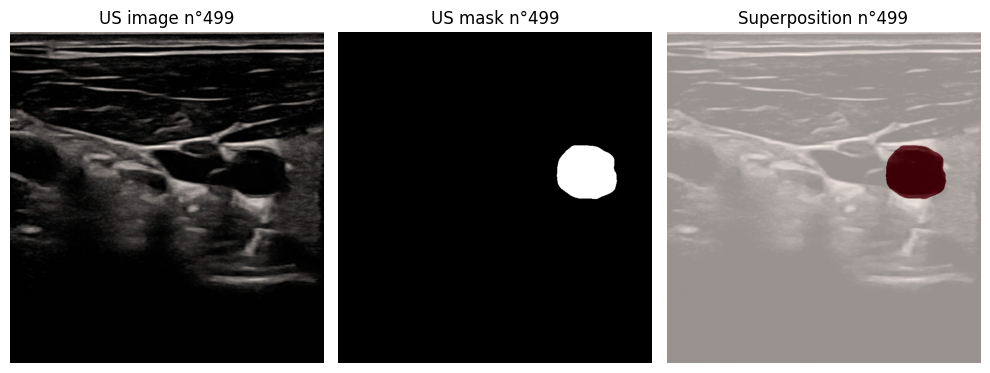

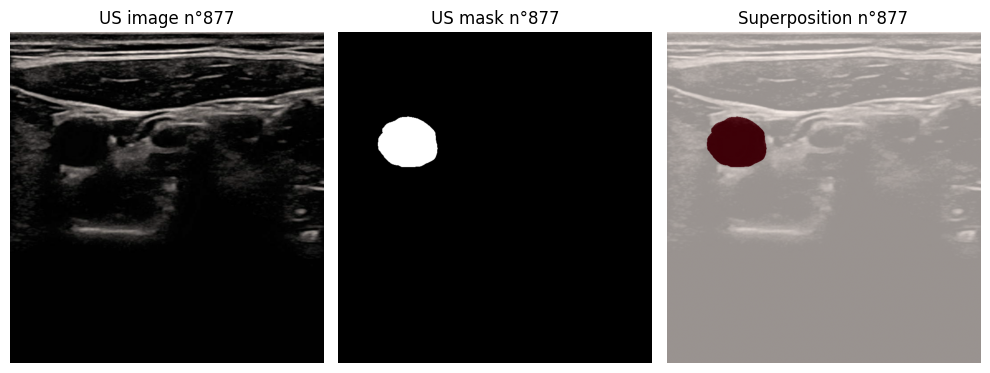

In [7]:
# Showing a few random cases : US image, US mask, superposition 
show_data(csv_dataset=all_data, num_display_samples=2)

In [8]:
# Creating the datasets and dataloaders accordingly to the dataset class
train_dataset, test_dataset, val_dataset, train_loader, test_loader, val_loader = building_datasets_dataloaders(data=all_data)

Train dataset length : 704
Test dataset length : 220
Val dataset length : 176

Train loader length : 176
Test loader length : 55
Val loader length : 44


# **2. Creating the Attention UNET model**

In [ ]:
class DoubleConv(nn.Module): 
    """
    Proceed feature extraction. Each layer learns patterns, 
    with a stable training (BatchNorm) and a feature complexity 
    detection (with the ReLU activation function). Two 3x3 kernel 
    convolutions are operated.  

    Attributes:
        in_channels (int): Number of channels in the input tensor (e.g., 3 for RGB). 
        out_channels (int): Number of channels produced by the convolution. 

        Input Shape: 
        (B, C_in, H, W).
        
        Output Shape: 
        (B, C_out, H, W).
    """
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv_op: nn.Sequential = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features=out_channels), 
            nn.ReLU(inplace=True), 

            nn.Conv2d(in_channels=out_channels, out_channels=out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_features=out_channels), 
            nn.ReLU(inplace=True)
        )
    def forward(self, x): 
        return self.conv_op(x)

In [9]:
class DownSample(nn.Module): 
    """
    Applies two 3x3 convolutions (Conv, BatchNorm, ReLU) 
    and a 2x2 max pooling, to reduce the image dimensions by 2. 
    We have deep, compressed features in the encoder part. 

    Attributes:
    in_channels (int): Number of channels in the input tensor. 
    out_channels (int): Number of channels produced by the convolution. 

    Input Shape: 
    (B, C_in, H, W).
    
    Output Shape: 
    tuple(torch.tensor, torch.tensor):
        down (torch.tensor): high resolution features for skip connections.
        p (torch.tensor): compressed features whith a reduced image dimensions (B, C_in, H//2, W//2).
    """
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv: DoubleConv = DoubleConv(in_channels=in_channels, out_channels=out_channels)
        self.pool: nn.MaxPool2d = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x): 
        down = self.conv(x) 
        p = self.pool(down)
        return down, p

In [10]:
class AttentionGate(nn.Module):
    """
    Create the attention block of the UNet, where g is 
    the decoder feature map (Guidance signal) and s the 
    skip connections feature map (noisy signal to be removed).
    Psi is then the attention map, telling the model how much
    signal to keep at each pixel. s*psi part remove irrelevant areas.
    Signals s and g will always have the same dimension of g. 

    Attributes:
        g_channels (int): Number of channels in the decoder gating signal. 
        s_channels (int): Number of channels in the skip connections signal.
        out_channels(int): Number of channels to compute the attention coefficients.

    Input Shape: 
        g: tensor of shape (B, g_channels, H_g, W_g) of the gating signal.
        s: tensor of shape (B, s_channels, H_s, W_s) of the skip connections signal.

    Output Shape: 
        tensor of shape (B, s_channels, H_g, W_g) of the filtered skip connections. 
    
    """
    def __init__(self, g_channels: int, s_channels: int, out_channels: int):
        super().__init__()
        self.Wg: nn.Sequential = nn.Sequential(
            nn.Conv2d(in_channels=g_channels, out_channels=out_channels, kernel_size=1),
            nn.BatchNorm2d(num_features=out_channels)
        )
        self.Ws: nn.Sequential = nn.Sequential(
            nn.Conv2d(in_channels=s_channels, out_channels=out_channels, kernel_size=1),
            nn.BatchNorm2d(num_features=out_channels)
        )
        self.psi: nn.Sequential = nn.Sequential(
            nn.Conv2d(in_channels=out_channels, out_channels=1, kernel_size=1),
            nn.Sigmoid()
        )
    def forward(self, g, s):
        s = F.interpolate(s, size=g.shape[2:], mode="bilinear", align_corners=True)
        g1 = self.Wg(g)
        s1 = self.Ws(s)
        out = F.relu(g1+s1)
        psi = self.psi(out)
        return s*psi

In [11]:
class UpSample(nn.Module): 
    """
    Takes the feature maps produced by the encoder to 
    generate segmentation masks. The bilinear interpolation upsamples 
    the decoder features, then we run the skip connections (att) and 
    concatenate them (to remove the noise). 

    Attributes:
        in_channels (int): Number of channels in the decoder gating signal. 
        skip_channels (int): Number of channels in the skip connections encoder signal.
        out_channels(int): Number of channels produced by the DoubleConv convolution. 

    Input Shape: 
        x: tensor of shape (B, in_channels, H_x, W_x) from deep features of lower layers. 
        skip: tensor of shape (B, s_channels, H_s, W_s) from the high resolution signal of 
        skip connection from the encoder. 

    Output Shape: 
        tensor of shape (B, out_channels, H_s, W_s) of the filtered feature map
        with the skip connections applied. 
    
    """
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.att: AttentionGate = AttentionGate(g_channels=in_channels, s_channels=skip_channels, out_channels=out_channels)
        self.conv: DoubleConv = DoubleConv(in_channels=in_channels+skip_channels, out_channels=out_channels)

    def forward(self, x, skip): 
        x = F.interpolate(input=x, size=skip.shape[2:], mode="bilinear", align_corners=True)
        skip = self.att(x, skip)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

In [12]:
class AttentionUNet(nn.Module):
    """
    Final model, that connects the encoder, decoder
    and the bottleneck, with the Attention Gate in the encoder, 
    to produce the segmentaion mask. No sigmoid function is applied at the end. 
    4 down sampling are applied, following a DoulbConv bottleneck process. 
    Finally, the up sampling part with the AttentionGate is done with 4 operations.

    Attributes:
        in_channels (int): Number of channels in the decoder gating signal. 
        num_classes (int): Number of classes that the model will produce at the end. 

    Input Shape: 
        x: tensor of shape (B, in_channels, H_x, W_x) that will go through the convolutions. 

    Output Shape: 
        tensor of shape (B, num_classes, H_x, W_x). 
    
    """
    def __init__(self, in_channels: int, num_classes: int):
        super().__init__()
        # Encoder
        self.down_conv1: DownSample = DownSample(in_channels=in_channels, out_channels=32)
        self.down_conv2: DownSample = DownSample(in_channels=32, out_channels=64)
        self.down_conv3: DownSample = DownSample(in_channels=64, out_channels=128)
        self.down_conv4: DownSample = DownSample(in_channels=128, out_channels=256)

        # Bottleneck
        self.bottleneck: DoubleConv = DoubleConv(in_channels=256, out_channels=512)
        
        # Decoder 
        self.up_conv1: UpSample = UpSample(in_channels=512, skip_channels= 256, out_channels=256)
        self.up_conv2: UpSample = UpSample(in_channels=256, skip_channels= 128, out_channels=128)
        self.up_conv3: UpSample = UpSample(in_channels=128, skip_channels= 64, out_channels=64)
        self.up_conv4: UpSample = UpSample(in_channels=64, skip_channels= 32, out_channels=32)

        self.out: nn.Conv2d = nn.Conv2d(in_channels=32, out_channels=num_classes, kernel_size=1)

    def forward(self, x):
        down_1, p1 = self.down_conv1(x)
        down_2, p2 = self.down_conv2(p1)
        down_3, p3 = self.down_conv3(p2)
        down_4, p4 = self.down_conv4(p3)

        b = self.bottleneck(p4)

        up_1 = self.up_conv1(b, down_4)
        up_2 = self.up_conv2(up_1, down_3)
        up_3 = self.up_conv3(up_2, down_2)
        up_4 = self.up_conv4(up_3, down_1)

        return self.out(up_4)

In [14]:
# Create the Attention UNet model
start: time = time.time()

model: AttentionUNet = AttentionUNet(in_channels=3, num_classes=1)
model.to(device=device)
print(f"{summary(model, input_size=(3, 256, 256))}")

end: time = time.time()
print(f"Execution time for the model : {end-start:.2f} s")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 256, 256]             896
       BatchNorm2d-2         [-1, 32, 256, 256]              64
              ReLU-3         [-1, 32, 256, 256]               0
            Conv2d-4         [-1, 32, 256, 256]           9,248
       BatchNorm2d-5         [-1, 32, 256, 256]              64
              ReLU-6         [-1, 32, 256, 256]               0
        DoubleConv-7         [-1, 32, 256, 256]               0
         MaxPool2d-8         [-1, 32, 128, 128]               0
        DownSample-9  [[-1, 32, 256, 256], [-1, 32, 128, 128]]               0
           Conv2d-10         [-1, 64, 128, 128]          18,496
      BatchNorm2d-11         [-1, 64, 128, 128]             128
             ReLU-12         [-1, 64, 128, 128]               0
           Conv2d-13         [-1, 64, 128, 128]          36,928
      BatchNorm2d-14    

# **3. Train and validation metrics**

In [15]:
def dice_loss(pred: torch.Tensor, target: torch.Tensor, epsilon: int = 1e-6) -> torch.Tensor:
    """
    Implements the Dice loss, in which the Dice = (2*intersection(A,B))/sum(A,B).

    Args:
        pred (torch.Tensor): prediction logits (raw values) tensor.
        target (torch.Tensor): target values tensor. 
        epsilon (int = 1e-6): value to avoid a 0 division. 

    Returns:
        torch.Tensor: a tensor of the mean soft Dice loss. 
    """
    if pred.shape != target.shape:
        raise ValueError(f"pred/outputs and target/inputs should have same shapes, got {pred.shape} and {target.shape}.")
    prob: torch.Tensor = torch.sigmoid(pred)  #prob (values btw 0 and 1)
    
    intersection: float = (prob * target).sum(dim=(1, 2, 3))
    union: float = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) # cardinality sum, not really the union
    dice: float = (2. * intersection + epsilon) / (union + epsilon)
    
    return 1 - dice.mean()  

In [16]:
def combined_loss(pred: torch.Tensor | None, target: torch.Tensor | None, alpha: int = 0.5) -> torch.Tensor:
    """
    Implements the combined loss, weighting the BCEWithLossLogits and Dice Loss
    by an alpha factor of 0.5. They then have the same weight. 

    Args:
        pred (torch.Tensor | None): prediction logits (raw values) tensor.
        target (torch.Tensor | None): target values tensor. 
        alpha (int = 0.5): weighting value.

    Returns:
        torch.Tensor: a tensor of the sum of the BCE Loss and soft Dice Loss.
    """
    if pred.shape != target.shape:
        raise ValueError(f"pred/outputs and target/inputs should have same shapes, got {pred.shape} and {target.shape}.")
    bce_loss_val: torch.Tensor = nn.BCEWithLogitsLoss()(pred, target)
    dice_loss_val: torch.Tensor = dice_loss(pred, target)

    return alpha * bce_loss_val + (1 - alpha) * dice_loss_val

In [17]:
def dice_score(pred: torch.Tensor, target: torch.Tensor, threshold: float = 0.5, epsilon: int = 1e-6) -> float:
    """
    Implements the Dice score, in which the Dice = (2*intersection(A,B))/sum(A,B). 
    It uses a threshold to compute the predicted binary masks. 

    Args:
        pred (torch.Tensor): prediction logits (raw values) tensor.
        target (torch.Tensor): target values tensor. 
        threshold: float = 0.5. 
        epsilon (int = 1e-6): value to avoid a 0 division. 

    Returns:
        float:  value of the mean of the soft Dice score.
    """
    if pred.shape != target.shape:
        raise ValueError(f"pred/outputs and target/inputs should have same shapes, got {pred.shape} and {target.shape}.")
    probabilities: torch.Tensor = torch.sigmoid(pred) #prob (values btw 0 and 1) - with pred as logits (floating points)
    binary_masks: float = (probabilities > threshold).float() #binary mask

    intersection: float = (binary_masks*target).sum(dim=(1,2,3))
    pred_sum: float = binary_masks.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3))
    dice: float = (2. * intersection + epsilon) / (pred_sum + epsilon)

    return dice.mean().item()

In [18]:
def iou_score(pred: torch.Tensor, target: torch.Tensor, threshold: float = 0.5, epsilon: int = 1e-6) -> float:
    """
    Implements the IoU (Intersection Over Union) score, 
    in which the IoU = (2*intersection(A,B))/[union(A,B) = sum(A,B) - intersection(A,B)]. 
    It uses a threshold to compute the predicted binary masks. 

    Args:
        pred (torch.Tensor): prediction logits (raw values) tensor.
        target (torch.Tensor): target values tensor. 
        threshold: float = 0.5. 
        epsilon (int = 1e-6): value to avoid a 0 division. 

    Returns:
        float: the value of the mean of the soft IoU score.
    """
    if pred.shape != target.shape:
        raise ValueError(f"pred/outputs and target/inputs should have same shapes, got {pred.shape} and {target.shape}.")
    probabilities: torch.Tensor = torch.sigmoid(pred) #prob (values btw 0 and 1) - with pred as logits (floating points)
    binary_masks: float = (probabilities > threshold).float() #binary mask

    intersection: float = (binary_masks*target).sum(dim=(1,2,3))
    union: float = binary_masks.sum(dim=(1,2,3)) + target.sum(dim=(1,2,3)) - intersection
    iou: float = (intersection + epsilon) / (union + epsilon)

    return iou.mean().item()

In [19]:
def hausdorff_distance(pred: np.ndarray, target: np.ndarray, max_dist: float) -> float:
    """
    Implements the normalized and bidirectionnal Hausdorff distance, 
    to compute the maximum distance between the prediction and target boundaries. 
    To have a better score, this distance must be as low as possible, as 0.0
    is an excellent Hausdorff distance, while 1.0 is mediocre. 
    It uses a max distance, which is in general the pixel diagonal 
    (the largest distance among the image). 

    Args:
        pred (np.ndarray): binary prediction masks (0.0 or 1.0).
        target (np.ndarray): binary ground truth (0.0 or 1.0). 
        max_dist (float): pixel diagonal value (np.sqrt(H^2 + W^2))

    Returns:
        float: the normalized Hausdorff distance value.
    """
    # Case where prediction is on the target (perfect case)
    if np.all(pred == target):
        return 0.0

    # Extract the coordinates 
    pred_coord: np.ndarray = np.argwhere(pred)
    target_coords: np.ndarray = np.argwhere(target)
    
    # Case where there's an empty array (crash prevent) 
    if len(pred_coord)==0 or len(target_coords)==0:
        return 1.0

    # Calculate the bidirectional hausdorff distance - select the max
    dist_pred_target: float = directed_hausdorff(pred_coord, target_coords)[0]
    dist_target_pred: float = directed_hausdorff(target_coords, pred_coord)[0]
    dist: float = max(dist_pred_target, dist_target_pred)

    # Where max dist is the image distance (diagonal of the image np.sqrt(w**2 + h**2))
    if dist > max_dist: 
        return 1.0
    return dist / max_dist

# **4. Training phase**

In [20]:
def train_one_epoch(
    loader: torch.utils.data.DataLoader, 
    model: torch.nn.Module, 
    optimizer: torch.optim.Optimizer,
    criterion: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], 
    device: torch
) -> float : 
    """
    Trains one epoch with a forward pass (calculating the loss)
    and a backward pass (computing the gradient). The training 
    loss is then calculated. 

    Args:
        loader (torch.utils.data.DataLoader): train loader. 
        model (torch.nn.Module): model to train. 
        optimizer (torch.optim.Optimizer): the AdamW optimizer with a weight decay of 1e-4.
        criterion (Callable[[torch.Tensor, torch.Tensor], torch.Tensor]): the loss function. 
        device (torch.device): the 'cuda' or 'cpu' device to load our model and data on. 

    Returns:
        float: the mean training loss value for this epoch step in a train batch. 
    """
    model.train()
    total_loss: float = 0.0
    for i, (imgs, masks) in enumerate(loader):
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(imgs)
        loss = criterion(outputs, masks)

        # Backward pass
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)

    return total_loss / len(loader.dataset)

In [21]:
def validation_step(
    loader: torch.utils.data.DataLoader, 
    model: torch.nn.Module, 
    criterion: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], 
    device: torch.device
) -> dict[str, list[float]]: 
    """
    Implements the validation process and compute some metrics 
    such as the validation mean loss, the validation mean soft 
    Dice score and the validation mean IoU. 
    
    Args:
        loader (torch.utils.data.DataLoader): validation loader. 
        model (torch.nn.Module): model to validate. 
        criterion (Callable[[torch.Tensor, torch.Tensor], torch.Tensor]): the loss function. 
        device (torch.device): the 'cuda' or 'cpu' device to load our model and data on. 

    Returns:
        dict[str, list[float]]: A dictionnary containing the list of validation metrics values. 
    """
    total_loss: float = 0.0
    total_dice, total_iou = 0.0, 0.0

    model.eval()
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)

            outputs = model(imgs)
            loss: float = criterion(outputs, masks)
            total_loss += loss.item() * imgs.size(0)

            total_dice += dice_score(outputs, masks) * imgs.size(0)
            total_iou += iou_score(outputs, masks) * imgs.size(0)
            
    n: int = len(loader.dataset)
    
    return {"val_loss" : total_loss / n, 
            "val_dice" : total_dice / n, 
            "val_iou" : total_iou / n
            }

In [22]:
def total_training(
    loader_train: torch.utils.data.DataLoader, 
    loader_val: torch.utils.data.DataLoader, 
    model: torch.nn.Module, 
    optimizer: torch.optim.Optimizer,
    criterion: Callable[[torch.Tensor, torch.Tensor], torch.Tensor], 
    device: torch.device, 
    num_epochs: int, 
    patience_scheduler: int, 
    patience_stopping: int
) -> tuple[dict[str, list[float]], float]:
    """
    Total training function calling both train_one_epoch 
    and validation_step. With its many arguments, it computes
    the training for the selected number of epochs and save
    the train and val metrics (loss, Dice and IoU). A scheduler
    for Early Stopping is also implemented. 
    
    Args:
        loader_train (torch.utils.data.DataLoader): train loader. 
        loader_val (torch.utils.data.DataLoader): val loader. 
        model (torch.nn.Module): model to validate. 
        optimizer (torch.optim.Optimizer): the AdamW optimizer with a weight decay of 1e-4. 
        criterion (Callable[[torch.Tensor, torch.Tensor], torch.Tensor]): the loss function. 
        device (torch.device): the 'cuda' or 'cpu' device to load our model and data on. 
        num_epochs (int): maximum selcted number of epochs (e.g. 20 or 40). 
        patience_scheduler (int): number of epochs for reducing the learning rate when there's no improvement. 
        patience_stopping (int): number of epochs to break the training process because there's no improvement.

    Returns:
        tuple[dict[str, list[float]], float]: A tuple containing the dictionnary of the 
        metrics mean final value and the minimum validation loss found during the training process. 
    """
    # Metrics, dictionnary to save them and progress bar 
    train_losses, val_losses, val_dices, val_ious = [],[],[],[]
    metrics_global_dict: dict[str, list[float]] = {
        "train_losses" : [], 
        "val_losses" : [],
        "val_dices": [], 
        "val_ious": []
    }

     # For the lr scheduler 
    val_loss_min: float = np.inf # infinity 
    patience_counter: int = 0
    scheduler: optim.lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, 
        mode='min', 
        factor=0.5, 
        patience=patience_scheduler
    )
    
    progress_bar: tqdm = tqdm(range(num_epochs), desc="Training Progress")

    for epoch in progress_bar : 
        train_loss: float = train_one_epoch(loader=loader_train, model=model, optimizer=optimizer, criterion=criterion, device=device) 
        metrics: dict[str, list[float]] = validation_step(loader=loader_val, model=model, criterion=criterion, device=device)

        # Append the metrics for each epoch 
        train_losses.append(train_loss)
        val_losses.append(metrics['val_loss'])
        val_dices.append(metrics['val_dice'])
        val_ious.append(metrics['val_iou'])

        # Display in the progress bar
        tqdm.write(f"\nFor epoch : {epoch+1} / {num_epochs} :")
        tqdm.write(f"- Train loss : {train_loss:.4f} | Val loss : {metrics['val_loss']:.4f}")
        tqdm.write(f"- Val dice : {metrics['val_dice']:.4f} | Val iou : {metrics['val_iou']:.4f}\n") 

         # Scheduler 
        scheduler.step(metrics['val_loss'])
        if metrics['val_loss']<val_loss_min:
            val_loss_min=metrics['val_loss']
            patience_counter = 0
        else : 
            patience_counter += 1
        if patience_counter > patience_stopping: 
            tqdm.write(f"-> Early stopping at epoch : {epoch+1}/{num_epochs}")
            break

    # Fill the metrics dictionnary 
    metrics_global_dict["train_losses"]  = train_losses
    metrics_global_dict["val_losses"]    = val_losses
    metrics_global_dict["val_dices"]     = val_dices
    metrics_global_dict["val_ious"]      = val_ious

    return metrics_global_dict, val_loss_min

In [24]:
# Loss functions dict
loss_fns: dict[str, any] = {
    "BCE Loss" : nn.BCEWithLogitsLoss(), 
    "Dice Loss" : dice_loss, 
    "Combined Loss" : combined_loss
}

# Hyperparameters grid
hyperparams_grid: dict[str, any] = {
    "loss_fns" : {
    "BCE Loss": loss_fns["BCE Loss"], 
    "Dice Loss" : loss_fns["Dice Loss"], 
    "Combined Loss" : loss_fns["Combined Loss"]
    },
    "num_epochs" : [20, 40], 
    "lrs_rates" : [1e-4, 1e-5]
}

# Tracking variables 
best_val_loss: float = float('inf')
best_hyperparams: dict[str, any] = {}
best_model_weights: dict[str, torch.Tensor] | None = None
metrics_best_dict: dict[str, list[float]] = {}

# For the Early Stopping 
patience_scheduler: int = 4
patience_stopping: int = 7

In [25]:
# Train the model 
start: time = time.time()

# Loop for testing the hyperparameters 
for loss_name, loss_fn in hyperparams_grid['loss_fns'].items():
    for max_epochs in hyperparams_grid['num_epochs']:  
        for lr in hyperparams_grid['lrs_rates']: 
            print(f" Loss function : {loss_name} | max epochs = {max_epochs} | lr = {lr}")
            # Re-initialization
            model: AttentionUNet = AttentionUNet(in_channels=3, num_classes=1).to(device)
            optimizer: torch.optim = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
            metrics_global_dict, current_min_loss = total_training(
                                loader_train=train_loader, 
                                loader_val=val_loader, 
                                model=model, 
                                optimizer=optimizer,
                                criterion=loss_fn, 
                                device=device, 
                                num_epochs=max_epochs, 
                                patience_scheduler=patience_scheduler, 
                                patience_stopping=patience_stopping
            ) 
            # Check for the best model
            if current_min_loss<best_val_loss: 
                best_val_loss = current_min_loss
                actual_nb_epochs = len(metrics_global_dict["train_losses"])
                best_hyperparams = {
                    "loss_name" : loss_name, 
                    "loss_fn" : loss_fn, 
                    "max_epochs" : max_epochs,    
                    "actual_nb_epochs" : actual_nb_epochs,
                    "lr" : lr, 
                    "val_loss" : current_min_loss
                }
                metrics_best_dict = metrics_global_dict
                best_model_weights = copy.deepcopy(model.state_dict())
                torch.save(best_model_weights, "best_modet.pth")
                print(f"New best model found, loss = {loss_name} | epochs = {actual_nb_epochs}/{max_epochs} | lr = {lr} | val_loss = {current_min_loss:.4f} \n")
        
# Choose the model with the lowest validation loss
final_model: AttentionUNet = AttentionUNet(in_channels=3, num_classes=1).to(device)
final_model.load_state_dict(best_model_weights)

# Display the best hyperparameters found
print(f"Best hyperparams found : loss function : {best_hyperparams['loss_name']} | at number of epochs : {best_hyperparams['actual_nb_epochs']}/{best_hyperparams['max_epochs']} | lr : {best_hyperparams["lr"]} | val loss : {best_hyperparams["val_loss"]:.4f}")

end: time = time.time()

 Loss function : BCE Loss | max epochs = 20 | lr = 0.0001


Training Progress:   5%|▌         | 1/20 [00:52<16:33, 52.29s/it]


For epoch : 1 / 20 :
- Train loss : 0.5199 | Val loss : 0.4343
- Val dice : 0.1134 | Val iou : 0.0687



Training Progress:  10%|█         | 2/20 [01:38<14:35, 48.66s/it]


For epoch : 2 / 20 :
- Train loss : 0.4041 | Val loss : 0.4679
- Val dice : 0.2988 | Val iou : 0.1834



...


For epoch : 38 / 40 :
- Train loss : 0.4990 | Val loss : 0.4979
- Val dice : 0.7802 | Val iou : 0.6705



Training Progress:  98%|█████████▊| 39/40 [30:45<00:46, 46.87s/it]


For epoch : 39 / 40 :
- Train loss : 0.4978 | Val loss : 0.4854
- Val dice : 0.8436 | Val iou : 0.7508



Training Progress: 100%|██████████| 40/40 [31:39<00:00, 47.48s/it]


For epoch : 40 / 40 :
- Train loss : 0.4920 | Val loss : 0.4869
- Val dice : 0.7997 | Val iou : 0.7017

Best hyperparams found : loss function : BCE Loss | at number of epochs : 40/40 | lr : 0.0001 | val loss : 0.0118

Execution time for the train : 16928.67 s, 282.14 min, 4.70 h


In [26]:
def metrics_plotting(
    metrics_best_dict: dict[str, list[float]]
) -> None : 
    """
    Plots the training and validation losses and the validation Dice 
    and IoU scores for the best model. 
    
    Args:
        metrics_best_dict (dict[str, list[float]]): dictionnary of the best model metrics values. 

    Returns:
        None.
    """
    metrics_plot: plt.figure = plt.figure(figsize=(20,10))

    # If the Ealry Stopping was triggered
    num_epochs: int = len(metrics_best_dict["train_losses"])
    
    # Train and val losses
    ax_train_val_losses: plt.axes = metrics_plot.add_subplot(1, 2, 1)
    ax_train_val_losses.plot(range(1, num_epochs+1), metrics_best_dict["train_losses"], label="Train loss", color='green')
    ax_train_val_losses.plot(range(1, num_epochs+1), metrics_best_dict["val_losses"], label="Val loss", color='orange')
    ax_train_val_losses.set_xlabel('Epochs', fontsize=16)
    ax_train_val_losses.set_ylabel('Losses', fontsize=16)
    ax_train_val_losses.set_title(f'Train and validation loss : {best_hyperparams['loss_name']}', fontsize=18)
    ax_train_val_losses.grid(True)
    ax_train_val_losses.legend(fontsize=14, title_fontsize=17)

    # Val metrics 
    ax_val_metrics: plt.axes = metrics_plot.add_subplot(1, 2, 2)
    ax_val_metrics.plot(range(1, num_epochs+1), metrics_best_dict["val_dices"], label="Val dices", color='blue')
    ax_val_metrics.plot(range(1, num_epochs+1), metrics_best_dict["val_ious"], label="Val ious", color='red')
    ax_val_metrics.set_xlabel('Epochs', fontsize=16)
    ax_val_metrics.set_ylabel('Metrics', fontsize=16)
    ax_val_metrics.set_title('Validation metrics : dice and iou score', fontsize=18)
    ax_val_metrics.grid(True)
    ax_val_metrics.legend(fontsize=14, title_fontsize=17)

    plt.tight_layout()
    plt.show()

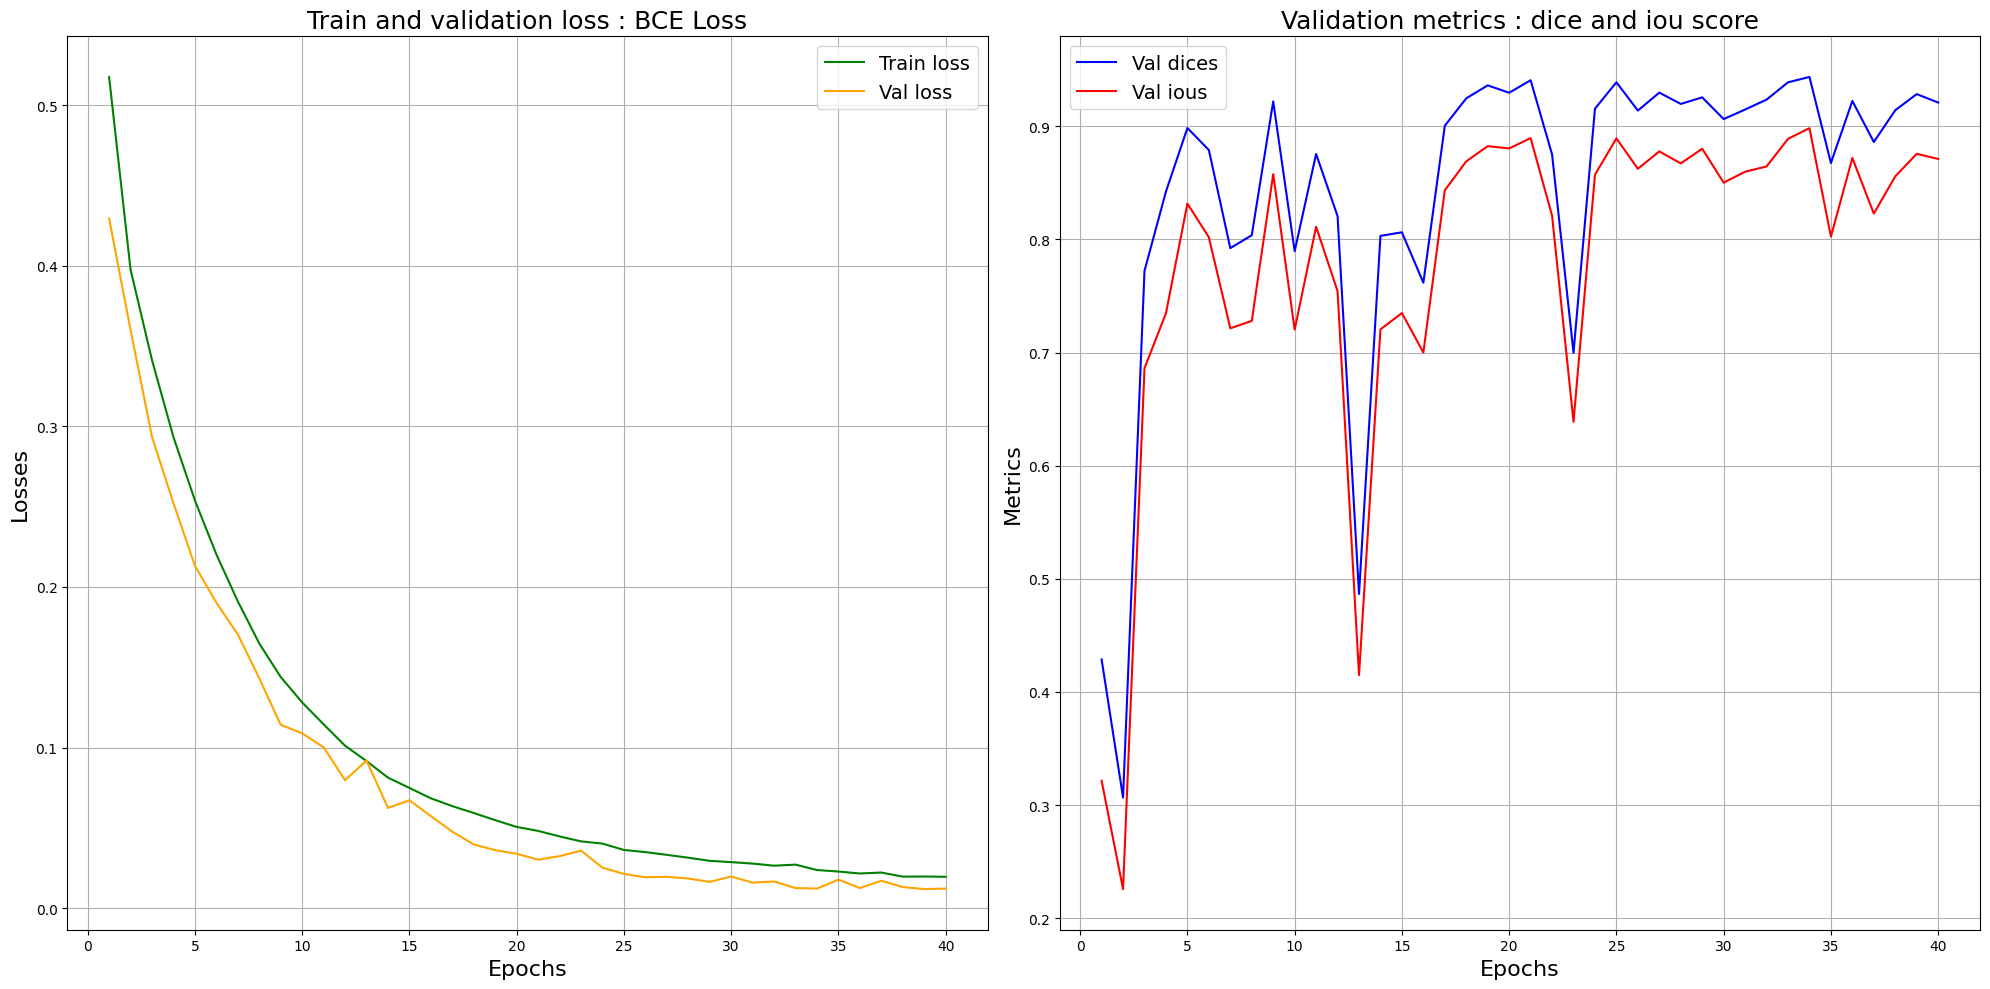

In [27]:
# Plotting the metric curves 

metrics_plotting(metrics_best_dict=metrics_best_dict)

# 5. Inference phase  

In [28]:
def inference(
    loader_test: torch.utils.data.DataLoader, 
    model: AttentionUNet, 
    device: torch.device,
    loss_fns_dict: dict,
    best_hyperparams: dict, 
    threshold: float = 0.5
) -> tuple[np.ndarray, np.ndarray, np.ndarray, int]:
    """
    Tests the best model on the testing new dataset. The 
    test loss, Hausdorff distance, Dice and IoU scores 
    are then displayed. 
    
    Args:
        loader_test (torch.utils.data.DataLoader): test loader. 
        model (torch.nn.Module): model to validate. 
        device (torch.device): the 'cuda' or 'cpu' device to load our model and data on. 
        loss_fns_dict (dict): dictionnary containing the name and loss functions associated. 
        best_hyperparams (dict): the dictionnary of the best resulting hyperparameters (such as the loss function 
        and its name, the number of epochs and the learning rate). 
        threshold (float = 0.5): threshold for computing the binary predicted masks.

    Returns:
        tuple[np.ndarray, np.ndarray, np.ndarray, int]: tuple of the images, masks and predictions resulting 
        of the inference, and the number of samples in the test dataset.
    """
    model.eval()

    # Initializing the test metrics 
    test_loss: float = 0.0 ; test_hausdorff: float = 0.0
    test_dice: float = 0.0 ; test_iou: float = 0.0
    num_batches: int = 0

    # List of test data points
    images_batch_list: list = []
    gt_masks_batch_list: list = []
    pred_masks_batch_list: list = []

    actual_loss_fn = loss_fns_dict[best_hyperparams["loss_name"]]

    # Iteration over the whole testing dataset 
    with torch.no_grad():
        for images, gt_masks in loader_test: 
            images, gt_masks = images.to(device), gt_masks.to(device)

            # For the hausdorff distance 
            h, w = images.shape[2], images.shape[3]
            max_dist: float = np.sqrt(h**2 + w**2)
            batch_size: int = images.size(0)
            
            # Calculate the predictions
            logits: float = model(images) # unnormalized scores (floating points)
            probabilities: torch.Tensor = torch.sigmoid(logits) # between 0 and 1 
            pred_masks: float = (probabilities > threshold).float() #binary mask (either 0.0 or 1.0)
            
            # Test Loss
            loss = actual_loss_fn(logits, gt_masks)
            test_loss += loss.item()
            
            # Converting binary masks and gt for metrics / plots
            gt_masks_np: np.ndarray = gt_masks.cpu().numpy().squeeze(1)
            pred_masks_np: np.ndarray = pred_masks.cpu().numpy().squeeze(1)
            
            # Test Hausdorff distance
            hausdorff_acumulator: float = 0.0
            for b in range(batch_size):
                hausdorff_acumulator += hausdorff_distance(pred_masks_np[b], gt_masks_np[b], max_dist) 
            test_hausdorff += hausdorff_acumulator / batch_size  
    
            # Test Dice and IoU
            test_dice += dice_score(logits, gt_masks) 
            test_iou += iou_score(logits, gt_masks) 
            
            # Transpose image for plotting = (B, C, H, W) into (B, H, W, C) 
            images_np: np.ndarray = images.cpu().numpy().transpose(0, 2, 3, 1)

            # Accumulating the metrics 
            images_batch_list.append(images_np)
            gt_masks_batch_list.append(gt_masks_np)
            pred_masks_batch_list.append(pred_masks_np)
            num_batches += 1
            
    # Concatenating the metrics 
    images_full_list: np.ndarray = np.concatenate(images_batch_list, axis=0)
    masks_full_list: np.ndarray = np.concatenate(gt_masks_batch_list, axis=0)
    pred_full_masks: np.ndarray = np.concatenate(pred_masks_batch_list, axis=0)
    total_sample: int = images_full_list.shape[0] # total count of test images 
    
    # Print the average test metrics 
    print(f"Average test loss ({best_hyperparams["loss_name"]}): {test_loss/num_batches:.4f}")
    print(f"Average test hausdorff distance : {test_hausdorff/num_batches:.4f}")
    print(f"Average test dice score : {test_dice/num_batches:.4f}")
    print(f"Average test iou score : {test_iou/num_batches:.4f}")

    return images_full_list, masks_full_list, pred_full_masks, total_sample


In [29]:
def inference_display(
    images_full_list: np.ndarray, 
    masks_full_list: np.ndarray,
    pred_full_masks: np.ndarray, 
    num_display_samples: int, 
    total_sample: int
) -> None:
    """
    Plots the US images, masks and predicted samples of the inference phase, 
    and the overlay of all of them (Green countour for the GT masks, 
    Red countour for the inference countour and yellow for their overlay). 
    It also prints the selected random indexes of images / masks for the predictions. 
    
    Args:
        images_full_list (np.ndarray): list of US test images. 
        masks_full_list (np.ndarray): list of US test masks. 
        pred_full_masks (np.ndarray): list of US test binary masks predictions. 
        num_display_samples (int): number of predictions we want to make. 
        total_sample (int): total number of samples in the test dataset. 

    Returns:
        None.
    """
    
    # Length of the predicted test dataset
    num_display_samples: int = min(num_display_samples, total_sample)
    sample_indices: np.ndarray = np.random.choice(total_sample, size=num_display_samples, replace=False)
    print(f"Sample indices : {sample_indices}")

    for i in range(num_display_samples):
        inference_plot: plt.figure = plt.figure(figsize=(10,5))
        idx: int = sample_indices[i]

        # Denomalize [0,1] instead of [-1,1] (image scale) for plotting and clip
        display_image = (images_full_list[idx] * 0.5) + 0.5
        display_image = np.clip(display_image, 0.0, 1.0)
        
        ax_img: plt.axes = inference_plot.add_subplot(2, 2, 1)
        ax_mask: plt.axes = inference_plot.add_subplot(2, 2, 2)
        ax_pred: plt.axes = inference_plot.add_subplot(2, 2, 3)
        ax_super_pred: plt.axes = inference_plot.add_subplot(2, 2, 4)

         # Display the image
        ax_img.imshow(display_image, cmap='gray')
        ax_img.set_title(f"US image n°{idx}")
        ax_img.axis("off")

        # Display the mask
        ax_mask.imshow(masks_full_list[idx], cmap='gray')
        ax_mask.set_title(f"US mask n°{idx}")
        ax_mask.axis("off")

        # Display the predicted mask
        ax_pred.imshow(pred_full_masks[idx], cmap='gray')
        ax_pred.set_title(f"Predicted US mask n°{idx}")
        ax_pred.axis("off")

        # Display the contour lines (GT: Green / Pred: Red / Overlay : Yellow) 
        overlay_mask = (masks_full_list[idx]==1) & (pred_full_masks[idx]==1)
        overlay_mask = overlay_mask.astype(np.float32)

        ax_super_pred.imshow(display_image, cmap='gray')
        ax_super_pred.contour(overlay_mask, colors='yellow', levels=[0.5], linewidths=4)
        ax_super_pred.contour(masks_full_list[idx], colors='green', levels=[0.5], linewidths=2)
        ax_super_pred.contour(pred_full_masks[idx], colors='red', levels=[0.5], linewidths=2)
        ax_super_pred.set_title(f"Boundaries (GT: Green / Pred: Red) n°{idx}")
        ax_super_pred.axis("off")

        plt.tight_layout()  
        plt.show()

In [30]:
# Testing the model on new data 
images_full_list, masks_full_list, pred_full_masks, total_sample = inference(
    loader_test = test_loader, 
    model = final_model, 
    device = device,
    loss_fns_dict = loss_fns,
    best_hyperparams = best_hyperparams, 
    threshold = 0.5
)

Average test loss (BCE Loss): 0.0144
Average test hausdorff distance : 0.0459
Average test dice score : 0.8929
Average test iou score : 0.8361


Sample indices : [ 72  81 207 134 152]


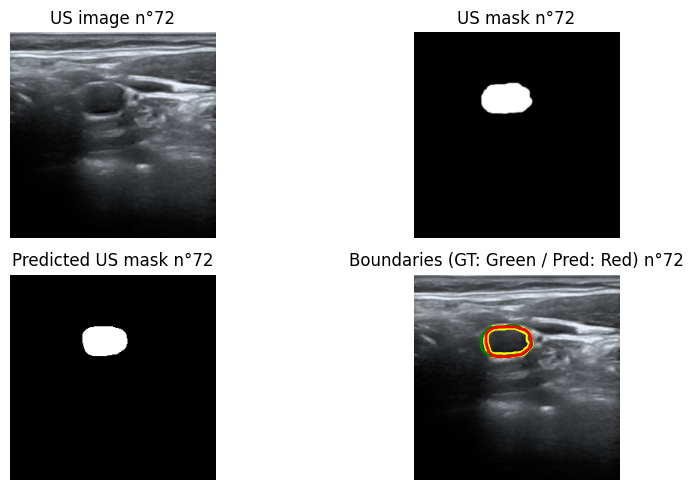

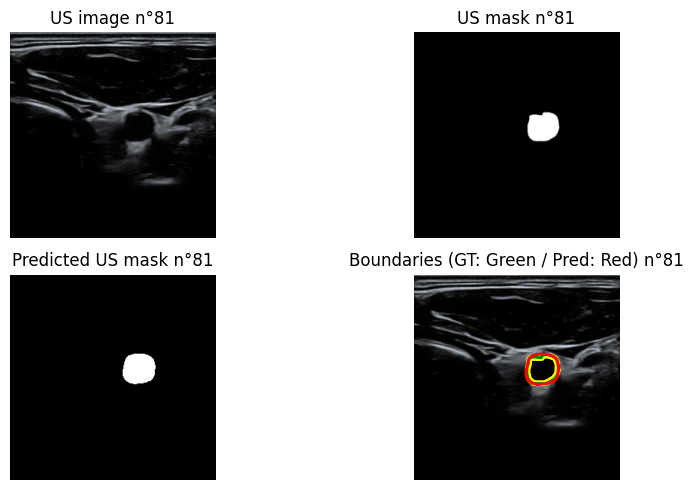

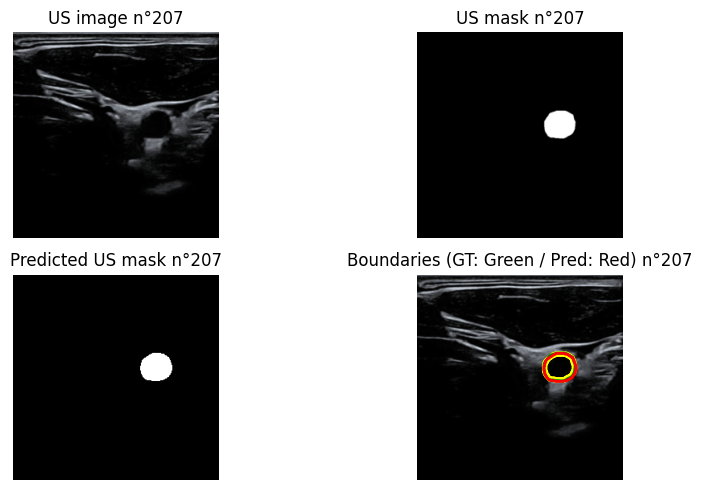

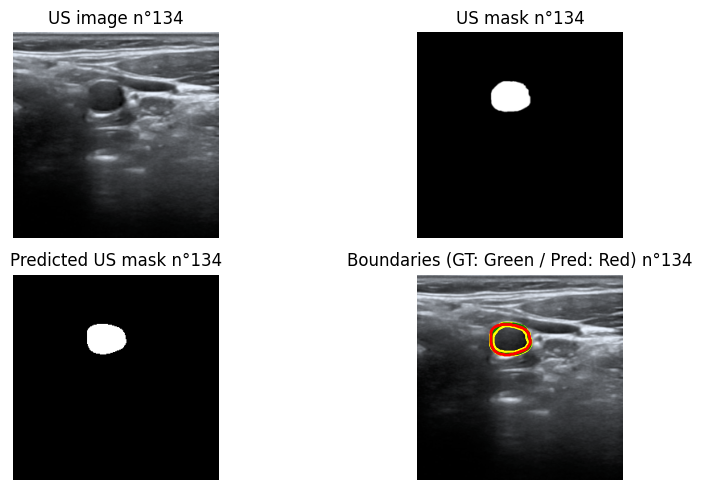

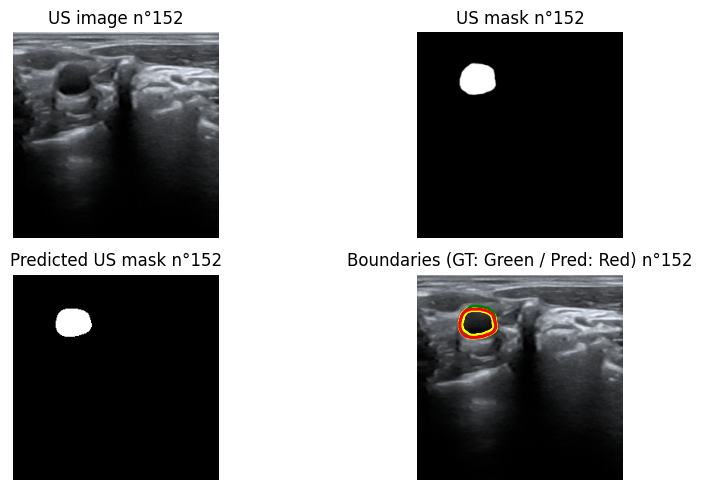

In [31]:
# Plotting the predictions 
inference_display(
    images_full_list = images_full_list, 
    masks_full_list = masks_full_list,
    pred_full_masks = pred_full_masks, 
    num_display_samples = 5, 
    total_sample = total_sample
)

# 5. Conclusion

The Attention-UNet performed brilliant inference, as we can note in the 5. Inference phase part of the Notebook. The prediction is correctly aligned with the GT mask in every prediction sample. As facts, the inference loss average is equal to 0.01 approximately, while the Hausdorff distance points to 0.04. The Dice score for the inference amounts to 0.89 and the IoU is a little bit lower, at 0.83. These interesting results come from 4.7 hours of training, while testing various hyperparameters. The one selected where the BCE loss function, 40 epochs, a 1e-4 learning rate, for a minimum validation loss of 0.01.  